In [1]:

from pathlib import Path
from importlib.metadata import version
import sys

import numpy
import pandas
import sklearn
import matplotlib
import seaborn
import jupyter
import xgboost

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Notebook working directory:", Path.cwd())

print("\nInstalled package versions:")
for package in [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "jupyter",
    "xgboost",
]:
    print(f"{package}: {version(package)}")


Python version: 3.13.7
Python executable: d:\smartphone-feature-selection\.venv\Scripts\python.exe
Notebook working directory: d:\smartphone-feature-selection\notebooks

Installed package versions:
numpy: 2.5.4
pandas: 3.0.6
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
jupyter: 1.1.1
xgboost: 3.4.1


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

# 项目根目录：Notebook 位于 notebooks 文件夹中
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "UCI HAR Dataset"

# 读取训练集和测试集
X_train = pd.read_csv(
    DATA_DIR / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)
y_train = pd.read_csv(
    DATA_DIR / "train" / "y_train.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]
subject_train = pd.read_csv(
    DATA_DIR / "train" / "subject_train.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

X_test = pd.read_csv(
    DATA_DIR / "test" / "X_test.txt",
    sep=r"\s+",
    header=None
)
y_test = pd.read_csv(
    DATA_DIR / "test" / "y_test.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]
subject_test = pd.read_csv(
    DATA_DIR / "test" / "subject_test.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

# 读取特征名称和活动标签名称
feature_info = pd.read_csv(
    DATA_DIR / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_index", "feature_name"]
)

activity_info = pd.read_csv(
    DATA_DIR / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

print("Data directory:", DATA_DIR)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("subject_train shape:", subject_train.shape)
print("subject_test shape:", subject_test.shape)
print("Number of feature names:", len(feature_info))
print("Number of activity labels:", len(activity_info))



Data directory: d:\smartphone-feature-selection\data\raw\UCI HAR Dataset
X_train shape: (7352, 561)
X_test shape: (2947, 561)
y_train shape: (7352,)
y_test shape: (2947,)
subject_train shape: (7352,)
subject_test shape: (2947,)
Number of feature names: 561
Number of activity labels: 6


In [4]:

# 1. 检查缺失值和无穷值

print("=== Data quality ===")

print("X_train missing values:", int(X_train.isna().sum().sum()))
print("X_test missing values:", int(X_test.isna().sum().sum()))

print("X_train contains infinite values:",
      bool(np.isinf(X_train.to_numpy()).any()))
print("X_test contains infinite values:",
      bool(np.isinf(X_test.to_numpy()).any()))

print("y_train missing values:", int(y_train.isna().sum()))
print("y_test missing values:", int(y_test.isna().sum()))

print("subject_train missing values:",
      int(subject_train.isna().sum()))
print("subject_test missing values:",
      int(subject_test.isna().sum()))


# 2. 检查特征名称是否重复

duplicate_count = int(
    feature_info["feature_name"].duplicated().sum()
)

print("\n=== Feature names ===")
print("Number of feature names:", len(feature_info))
print("Number of duplicated feature names:", duplicate_count)

if duplicate_count > 0:
    print("Duplicated names:")
    print(
        feature_info.loc[
            feature_info["feature_name"].duplicated(keep=False),
            "feature_name"
        ].tolist()[:20]
    )


# 3. 检查活动标签是否合法

print("\n=== Activity labels ===")

print("Training labels:", sorted(y_train.unique().tolist()))
print("Testing labels:", sorted(y_test.unique().tolist()))
print("Expected labels:",
      sorted(activity_info["activity_id"].tolist()))

unknown_train_labels = (
    set(y_train.unique()) - set(activity_info["activity_id"])
)
unknown_test_labels = (
    set(y_test.unique()) - set(activity_info["activity_id"])
)

print("Unknown training labels:", sorted(unknown_train_labels))
print("Unknown testing labels:", sorted(unknown_test_labels))


# 4. 检查训练集和测试集的参与者编号

train_subjects = set(subject_train.unique())
test_subjects = set(subject_test.unique())

print("\n=== Participants ===")
print("Training participants:", sorted(train_subjects))
print("Number of training participants:", len(train_subjects))

print("Testing participants:", sorted(test_subjects))
print("Number of testing participants:", len(test_subjects))

print("Participants appearing in both sets:",
      sorted(train_subjects & test_subjects))


=== Data quality ===
X_train missing values: 0
X_test missing values: 0
X_train contains infinite values: False
X_test contains infinite values: False
y_train missing values: 0
y_test missing values: 0
subject_train missing values: 0
subject_test missing values: 0

=== Feature names ===
Number of feature names: 561
Number of duplicated feature names: 84
Duplicated names:
['fBodyAcc-bandsEnergy()-1,8', 'fBodyAcc-bandsEnergy()-9,16', 'fBodyAcc-bandsEnergy()-17,24', 'fBodyAcc-bandsEnergy()-25,32', 'fBodyAcc-bandsEnergy()-33,40', 'fBodyAcc-bandsEnergy()-41,48', 'fBodyAcc-bandsEnergy()-49,56', 'fBodyAcc-bandsEnergy()-57,64', 'fBodyAcc-bandsEnergy()-1,16', 'fBodyAcc-bandsEnergy()-17,32', 'fBodyAcc-bandsEnergy()-33,48', 'fBodyAcc-bandsEnergy()-49,64', 'fBodyAcc-bandsEnergy()-1,24', 'fBodyAcc-bandsEnergy()-25,48', 'fBodyAcc-bandsEnergy()-1,8', 'fBodyAcc-bandsEnergy()-9,16', 'fBodyAcc-bandsEnergy()-17,24', 'fBodyAcc-bandsEnergy()-25,32', 'fBodyAcc-bandsEnergy()-33,40', 'fBodyAcc-bandsEnergy()-4

In [5]:

# 统计训练集和测试集中每种活动的样本数量

train_distribution = (
    y_train.value_counts()
    .sort_index()
    .rename_axis("activity_id")
    .reset_index(name="sample_count")
    .merge(activity_info, on="activity_id", how="left")
)

test_distribution = (
    y_test.value_counts()
    .sort_index()
    .rename_axis("activity_id")
    .reset_index(name="sample_count")
    .merge(activity_info, on="activity_id", how="left")
)

print("=== Training set activity distribution ===")
print(train_distribution.to_string(index=False))

print("\n=== Test set activity distribution ===")
print(test_distribution.to_string(index=False))


=== Training set activity distribution ===
 activity_id  sample_count      activity_name
           1          1226            WALKING
           2          1073   WALKING_UPSTAIRS
           3           986 WALKING_DOWNSTAIRS
           4          1286            SITTING
           5          1374           STANDING
           6          1407             LAYING

=== Test set activity distribution ===
 activity_id  sample_count      activity_name
           1           496            WALKING
           2           471   WALKING_UPSTAIRS
           3           420 WALKING_DOWNSTAIRS
           4           491            SITTING
           5           532           STANDING
           6           537             LAYING


In [6]:

# 检查哪些特征名称出现了多次
feature_name_counts = (
    feature_info.groupby("feature_name")
    .size()
    .reset_index(name="count")
)

duplicate_name_summary = (
    feature_name_counts[
        feature_name_counts["count"] > 1
    ]
    .sort_values("count", ascending=False)
)

print(
    "Number of distinct names occurring more than once:",
    len(duplicate_name_summary)
)

print(
    "Number of feature rows belonging to duplicated-name groups:",
    int(
        feature_info["feature_name"].isin(
            duplicate_name_summary["feature_name"]
        ).sum()
    )
)

print("\nRepeated feature names and their counts:")
print(duplicate_name_summary.to_string(index=False))


Number of distinct names occurring more than once: 42
Number of feature rows belonging to duplicated-name groups: 126

Repeated feature names and their counts:
                    feature_name  count
     fBodyAcc-bandsEnergy()-1,16      3
     fBodyAcc-bandsEnergy()-1,24      3
      fBodyAcc-bandsEnergy()-1,8      3
    fBodyAcc-bandsEnergy()-17,24      3
    fBodyAcc-bandsEnergy()-17,32      3
    fBodyAcc-bandsEnergy()-25,32      3
    fBodyAcc-bandsEnergy()-25,48      3
    fBodyAcc-bandsEnergy()-33,40      3
    fBodyAcc-bandsEnergy()-33,48      3
    fBodyAcc-bandsEnergy()-41,48      3
    fBodyAcc-bandsEnergy()-49,56      3
    fBodyAcc-bandsEnergy()-49,64      3
    fBodyAcc-bandsEnergy()-57,64      3
     fBodyAcc-bandsEnergy()-9,16      3
 fBodyAccJerk-bandsEnergy()-1,16      3
 fBodyAccJerk-bandsEnergy()-1,24      3
  fBodyAccJerk-bandsEnergy()-1,8      3
fBodyAccJerk-bandsEnergy()-17,24      3
fBodyAccJerk-bandsEnergy()-17,32      3
fBodyAccJerk-bandsEnergy()-25,32      3


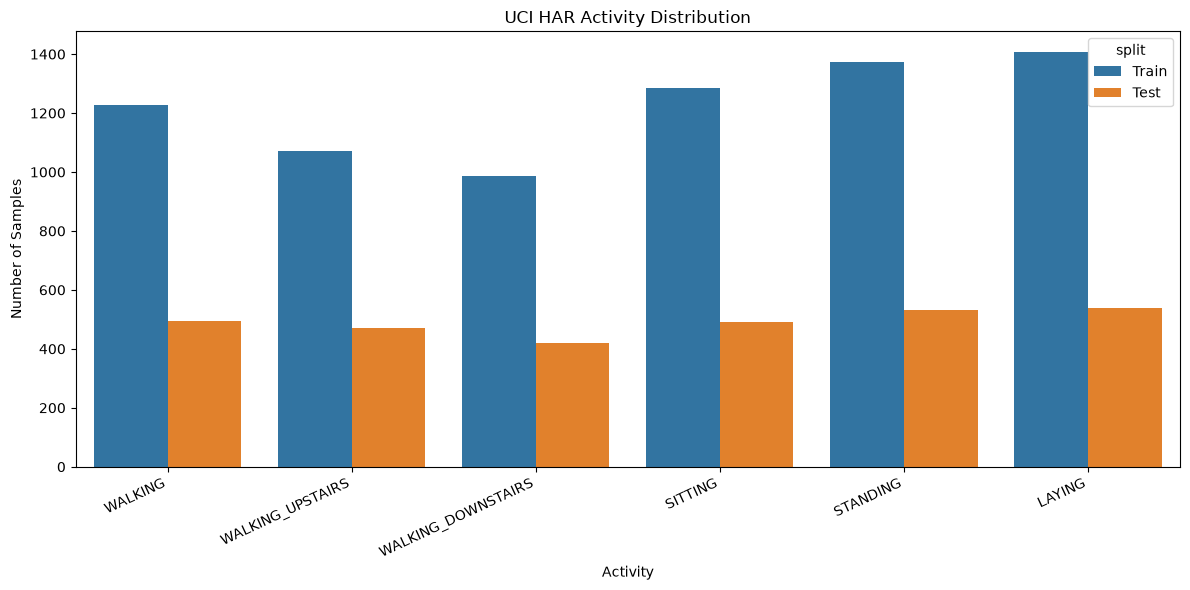

Figure saved to: d:\smartphone-feature-selection\results\figures\activity_distribution.png


In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 合并训练集和测试集的活动分布
train_plot_data = train_distribution.copy()
train_plot_data["split"] = "Train"

test_plot_data = test_distribution.copy()
test_plot_data["split"] = "Test"

plot_data = pd.concat(
    [train_plot_data, test_plot_data],
    ignore_index=True
)

# 绘制对比图
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="activity_name",
    y="sample_count",
    hue="split"
)

plt.title("UCI HAR Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

# 保存图片到项目的结果目录
project_root = Path.cwd().parent
figure_dir = project_root / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "activity_distribution.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)



## 数据理解实验记录

### 1. 数据集基本信息

- 训练集：7,352 个样本，561 个特征。
- 测试集：2,947 个样本，561 个特征。
- 总样本数：10,299。
- 特征名称数量：561。
- 活动类别数量：6。

### 2. 数据质量检查

- 训练集和测试集的特征矩阵均未发现缺失值。
- 训练集和测试集的特征矩阵均未发现无穷值。
- 训练集和测试集均包含活动标签 1—6。
- 未发现未知活动标签。
- 活动标签和参与者编号均未发现缺失值。

### 3. 参与者划分检查

- 训练集包含 21 位参与者。
- 测试集包含另外 9 位参与者。
- 两个数据集的参与者编号没有交集。

本实验保留数据集官方提供的训练集与测试集划分。

### 4. 重复特征名称检查

- 特征名称总数：561。
- 出现重复的不同名称数：42。
- 属于重复名称组的特征条目数：126。
- 使用 pandas 的 duplicated() 统计得到的重复条目数：84。

这里发现的是特征名称字符串重复，并未据此认定对应的数据列数值完全相同。

因此，本阶段保留全部 561 个特征。后续使用特征列索引区分同名特征，不因名称重复而删除数据列。

### 5. 六类活动的样本分布

训练集：

| 活动类别 | 样本数 |
|---|---:|
| 走路 | 1,226 |
| 上楼 | 1,073 |
| 下楼 | 986 |
| 坐 | 1,286 |
| 站立 | 1,374 |
| 躺下 | 1,407 |

测试集：

| 活动类别 | 样本数 |
|---|---:|
| 走路 | 496 |
| 上楼 | 471 |
| 下楼 | 420 |
| 坐 | 491 |
| 站立 | 532 |
| 躺下 | 537 |

### 6. 可视化结果

活动分布图：

`results/figures/activity_distribution.png`

### 7. 本阶段结论

数据集的样本数量、特征维度、活动标签和参与者划分均符合预期。

未发现缺失值或无穷值。检查发现部分特征名称重复，但本阶段没有删除任何特征列。

下一阶段将使用全部 561 个特征训练基线分类模型，为后续特征选择实验提供比较基准。
